In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Load Iris dataset
from sklearn.datasets import load_iris

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Machine learning algorithms
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Model evaluation
from sklearn.metrics import adjusted_rand_score

# Model saving and loading
import joblib
import pickle

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add actual flower species
df["Species"] = iris.target

# Display first 10 records
print("First 10 rows:")
display(df.head(10))

# Dataset shape
print("\nDataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())

First 10 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
5,5.4,3.9,1.7,0.4,0
6,4.6,3.4,1.4,0.3,0
7,5.0,3.4,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0



Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [3]:
# Select input features
X = iris.data

# Scale the dataset
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
scaled_df = pd.DataFrame(
    X_scaled,
    columns=iris.feature_names
)

print("Scaled Dataset:")
display(scaled_df.head())

print("\nScaled Feature Means:")
print(scaled_df.mean().round(2))

Scaled Dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444



Scaled Feature Means:
sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64


In [4]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model and predict clusters
clusters = kmeans.fit_predict(X_scaled)

# Add predicted clusters to DataFrame
df["Cluster"] = clusters

print("K-Means Clustering Completed!")

print("\nCluster Assignments:")
display(df.head(10))

# Count flowers in each cluster
print("\nNumber of flowers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

K-Means Clustering Completed!

Cluster Assignments:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1
5,5.4,3.9,1.7,0.4,0,1
6,4.6,3.4,1.4,0.3,0,1
7,5.0,3.4,1.5,0.2,0,1
8,4.4,2.9,1.4,0.2,0,1
9,4.9,3.1,1.5,0.1,0,1



Number of flowers in each cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


In [5]:
# Display cluster centers
print("Cluster Centers (Scaled Data):")

cluster_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=iris.feature_names
)

display(cluster_centers)

Cluster Centers (Scaled Data):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050220,-0.883376,0.347738,0.281527
1,-1.014579,0.853263,-1.304987,-1.254893
2,1.135970,0.088422,0.996155,1.017526


In [6]:
# Convert cluster centers back to original scale
original_centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers_df = pd.DataFrame(
    original_centers,
    columns=iris.feature_names
)

print("Cluster Centers in Original Units:")
display(centers_df.round(2))

Cluster Centers in Original Units:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.80,2.67,4.37,1.41
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


In [7]:
# Create PCA model with 2 components
pca = PCA(n_components=2)

# Reduce the scaled dataset to 2 dimensions
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

print("PCA Transformation Completed!")

print("\nReduced Dataset:")
display(pca_df.head(10))

print("\nOriginal Shape:", X_scaled.shape)
print("Reduced Shape:", X_pca.shape)

PCA Transformation Completed!

Reduced Dataset:


,PC1,PC2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835
5,-2.075631,1.489178
6,-2.444029,0.047644
7,-2.232847,0.223148
8,-2.334640,-1.115328
9,-2.184328,-0.469014



Original Shape: (150, 4)
Reduced Shape: (150, 2)


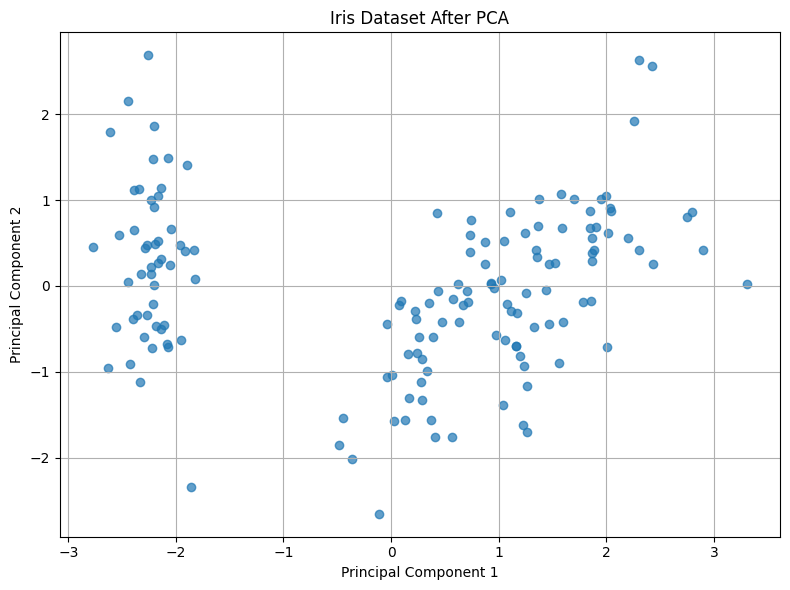

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.7
)

plt.title("Iris Dataset After PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.grid(True)
plt.tight_layout()

plt.savefig("iris_pca_visualization.png", dpi=300)

plt.show()

In [9]:
print("Explained Variance Ratio:")

for i, variance in enumerate(
    pca.explained_variance_ratio_,
    start=1
):
    print(f"PC{i}: {variance:.4f}")

print(
    "\nTotal Explained Variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Explained Variance Ratio:
PC1: 0.7296
PC2: 0.2285

Total Explained Variance: 95.81 %


In [10]:
# Create K-Means model
iris_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train and predict clusters
predicted_clusters = iris_kmeans.fit_predict(X_scaled)

print("Iris Flower Clustering Completed!")

Iris Flower Clustering Completed!


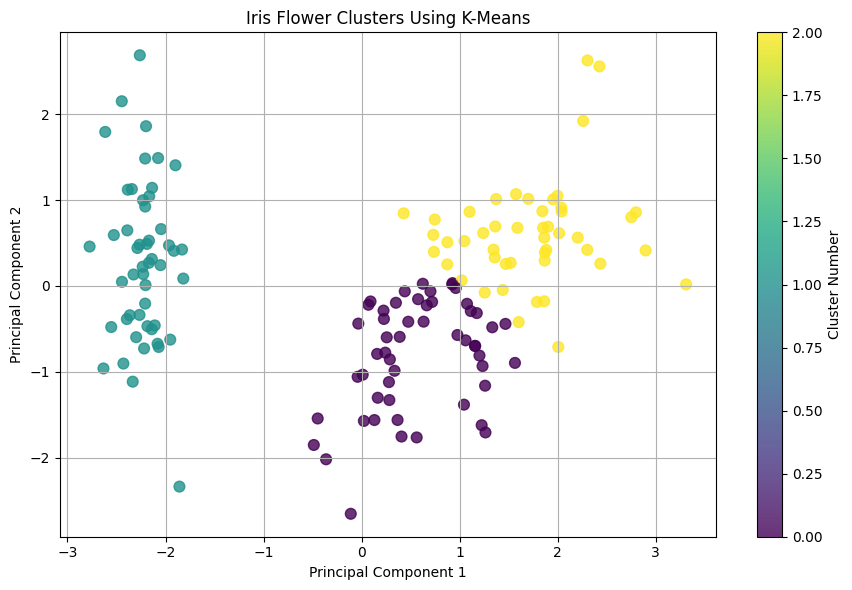

In [11]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=predicted_clusters,
    cmap="viridis",
    s=60,
    alpha=0.8
)

plt.title("Iris Flower Clusters Using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(scatter, label="Cluster Number")

plt.grid(True)
plt.tight_layout()

plt.savefig("iris_kmeans_clusters.png", dpi=300)

plt.show()

In [12]:
# Create comparison DataFrame
comparison_df = pd.DataFrame({
    "Actual Species": iris.target,
    "Predicted Cluster": predicted_clusters
})

print("Actual Species vs Predicted Clusters:")

display(
    pd.crosstab(
        comparison_df["Actual Species"],
        comparison_df["Predicted Cluster"]
    )
)

Actual Species vs Predicted Clusters:


Predicted Cluster,0,1,2
Actual Species,,,
0,0,50,0
1,39,0,11
2,14,0,36


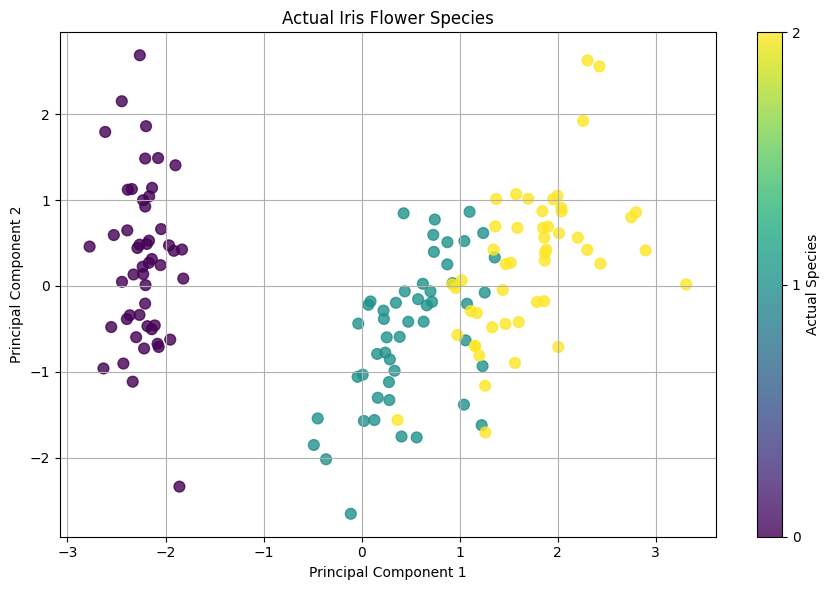

In [13]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=iris.target,
    cmap="viridis",
    s=60,
    alpha=0.8
)

plt.title("Actual Iris Flower Species")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(
    scatter,
    ticks=[0, 1, 2],
    label="Actual Species"
)

plt.grid(True)
plt.tight_layout()

plt.savefig("iris_actual_species.png", dpi=300)

plt.show()

In [14]:
ari_score = adjusted_rand_score(
    iris.target,
    predicted_clusters
)

print("Adjusted Rand Index:", round(ari_score, 4))

Adjusted Rand Index: 0.6201


In [15]:
# Create final output DataFrame
final_results = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

final_results["Actual Species"] = iris.target
final_results["Predicted Cluster"] = predicted_clusters

# Save CSV
final_results.to_csv(
    "iris_clustering_results.csv",
    index=False
)

print("Iris clustering results saved successfully!")

display(final_results.head(10))

Iris clustering results saved successfully!


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Actual Species,Predicted Cluster
0,5.1,3.5,1.4,0.2,0,1
1,4.9,3.0,1.4,0.2,0,1
2,4.7,3.2,1.3,0.2,0,1
3,4.6,3.1,1.5,0.2,0,1
4,5.0,3.6,1.4,0.2,0,1
5,5.4,3.9,1.7,0.4,0,1
6,4.6,3.4,1.4,0.3,0,1
7,5.0,3.4,1.5,0.2,0,1
8,4.4,2.9,1.4,0.2,0,1
9,4.9,3.1,1.5,0.1,0,1


In [16]:
# Create K-Means model
practice_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Apply K-Means
practice_clusters = practice_kmeans.fit_predict(
    X_scaled
)

# Print cluster centers
print("Cluster Centers:")

practice_centers = pd.DataFrame(
    practice_kmeans.cluster_centers_,
    columns=iris.feature_names
)

display(practice_centers)

# Print cluster assignments
print("\nFirst 10 Cluster Assignments:")
print(practice_clusters[:10])

Cluster Centers:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050220,-0.883376,0.347738,0.281527
1,-1.014579,0.853263,-1.304987,-1.254893
2,1.135970,0.088422,0.996155,1.017526



First 10 Cluster Assignments:
[1 1 1 1 1 1 1 1 1 1]


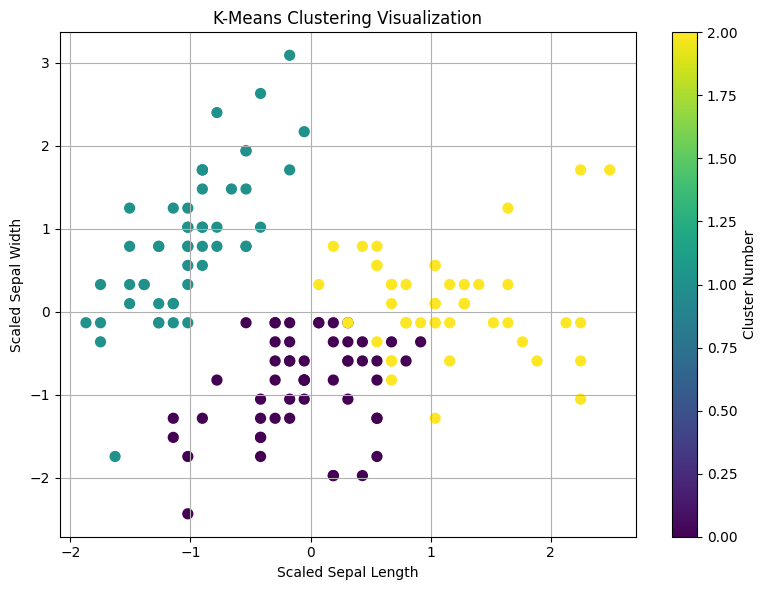

In [17]:
# Create scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=practice_clusters,
    cmap="viridis",
    s=50
)

plt.title("K-Means Clustering Visualization")
plt.xlabel("Scaled Sepal Length")
plt.ylabel("Scaled Sepal Width")

plt.colorbar(label="Cluster Number")

plt.grid(True)
plt.tight_layout()

plt.savefig("practice_kmeans_visualization.png", dpi=300)

plt.show()

In [20]:
# Create PCA model
practice_pca = PCA(n_components=2)

# Apply PCA
reduced_data = practice_pca.fit_transform(X_scaled)

# Display reduced dataset
print("Reduced Dataset:")
display(pd.DataFrame(
    reduced_data,
    columns=["PC1", "PC2"]
))

print("Original Dimensions:", X_scaled.shape)
print("Reduced Dimensions:", reduced_data.shape)

Reduced Dataset:


,PC1,PC2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835
...,...,...
145,1.870503,0.386966
146,1.564580,-0.896687
147,1.521170,0.269069
148,1.372788,1.011254


Original Dimensions: (150, 4)
Reduced Dimensions: (150, 2)


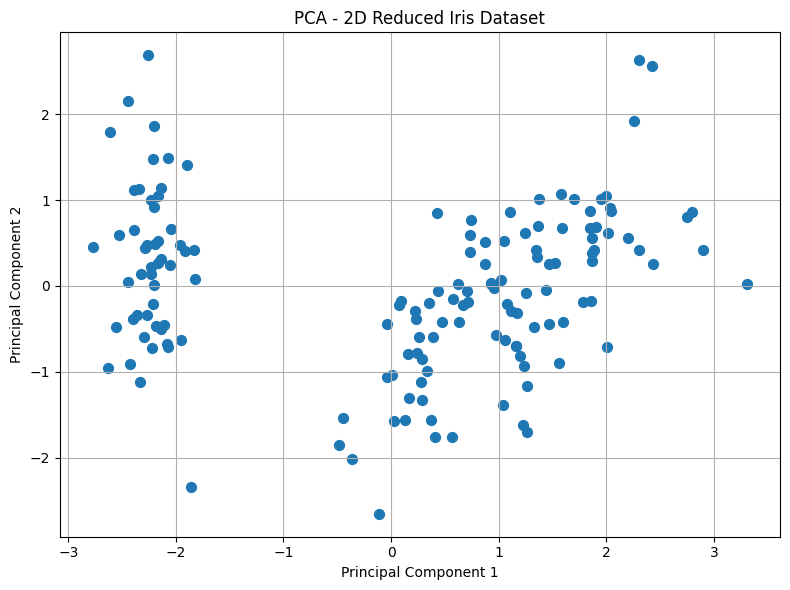

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    reduced_data[:, 0],
    reduced_data[:, 1],
    s=50
)

plt.title("PCA - 2D Reduced Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.grid(True)
plt.tight_layout()

plt.savefig("practice_pca_2d.png", dpi=300)

plt.show()

In [21]:
# Get explained variance ratio
variance_ratio = practice_pca.explained_variance_ratio_

print("Explained Variance Ratio:")

for i, value in enumerate(variance_ratio, start=1):
    print(f"PC{i}: {value:.4f}")

# Calculate total variance
total_variance = sum(variance_ratio)

print("\nTotal Explained Variance Ratio:",
      round(total_variance, 4))

print("Total Explained Variance Percentage:",
      round(total_variance * 100, 2), "%")

Explained Variance Ratio:
PC1: 0.7296
PC2: 0.2285

Total Explained Variance Ratio: 0.9581
Total Explained Variance Percentage: 95.81 %


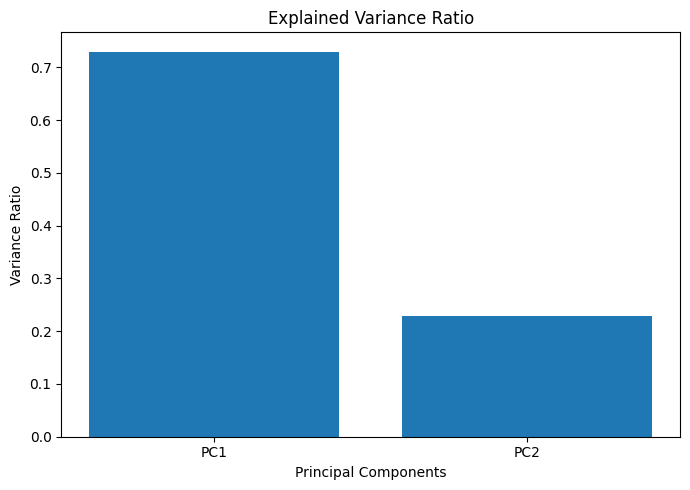

In [22]:
plt.figure(figsize=(7, 5))

components = ["PC1", "PC2"]

plt.bar(
    components,
    variance_ratio
)

plt.title("Explained Variance Ratio")
plt.xlabel("Principal Components")
plt.ylabel("Variance Ratio")

plt.tight_layout()

plt.savefig("explained_variance_ratio.png", dpi=300)

plt.show()

In [24]:
# Store inertia values
wcss = []

# Test different cluster numbers
for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

print("WCSS Values:")
print(wcss)

WCSS Values:
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049, 81.54439095511782, 72.6311438266719, 62.540605695781245, 55.119492805290584, 47.39103517634709]


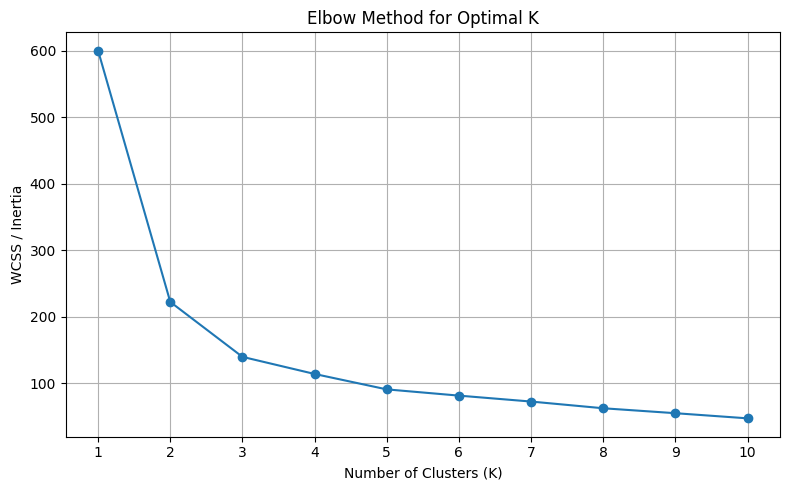

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")

plt.xticks(range(1, 11))
plt.grid(True)

plt.tight_layout()

plt.savefig("elbow_method.png", dpi=300)

plt.show()

In [26]:
# Save K-Means model
joblib.dump(
    iris_kmeans,
    "iris_kmeans_model.joblib"
)

print("Model saved using Joblib!")

# Load saved model
loaded_model = joblib.load(
    "iris_kmeans_model.joblib"
)

print("Model loaded successfully!")

# Predict using loaded model
loaded_predictions = loaded_model.predict(
    X_scaled
)

print("\nFirst 10 Predictions:")
print(loaded_predictions[:10])

Model saved using Joblib!
Model loaded successfully!

First 10 Predictions:
[1 1 1 1 1 1 1 1 1 1]


In [27]:
# Save model using Pickle
with open("iris_kmeans_model.pkl", "wb") as file:
    pickle.dump(iris_kmeans, file)

print("Model saved using Pickle!")

# Load model using Pickle
with open("iris_kmeans_model.pkl", "rb") as file:
    loaded_pickle_model = pickle.load(file)

print("Model loaded successfully!")

# Make predictions
pickle_predictions = loaded_pickle_model.predict(
    X_scaled
)

print("\nFirst 10 Predictions:")
print(pickle_predictions[:10])

Model saved using Pickle!
Model loaded successfully!

First 10 Predictions:
[1 1 1 1 1 1 1 1 1 1]


In [28]:
# Compare predictions from original and loaded models
print(
    "Joblib predictions match:",
    np.array_equal(predicted_clusters, loaded_predictions)
)

print(
    "Pickle predictions match:",
    np.array_equal(predicted_clusters, pickle_predictions)
)

Joblib predictions match: True
Pickle predictions match: True
